<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">هفتهٔ دهم | از تحلیل داده تا مقایسهٔ چند مدل</strong><div>المپیاد هوش مصنوعی · مسئله: حدس برچسب بقای ثبت‌شده در دادهٔ Titanic با چند ویژگی مسافر. ابتدا نمایش عددی داده و خط مبنا را خودمان می‌سازیم؛ سپس چند مدل آماده را با یک رابط مشترک می‌سنجیم. کدهای آموزشی از اینترنت داده را می‌گیرند و با فایل همراه، آفلاین هم اجرا می‌شوند.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #be185d;border-radius:8px;background:rgba(236,72,153,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">قرارداد علمی آزمایش</strong><div>ما دربارهٔ مسافران ثبت‌شده در یک دادهٔ تاریخی کار می‌کنیم. <code>Survived</code> هدفِ صفر/یک است. ویژگی‌ها: <code>Pclass</code>، <code>Fare</code>، <code>Sex</code> و <code>Embarked</code>. این انتخاب، اثر علّی یا ارزش‌گذاری دربارهٔ افراد را ثابت نمی‌کند. <code>Name</code>، <code>PassengerId</code> و ستون هدف وارد ویژگی‌ها نمی‌شوند. دو مقدار خالی <code>Embarked</code> را با یک دستهٔ مستقل نشان می‌دهیم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">داده را ببین</strong><div>فایل را اجرا و پنج سطر اول را بررسی کن. پاسخِ پیش‌بینی در کدام ستون است؟ در نبود اینترنت، فایل <code>data/titanic_real.csv</code> کنار نوت‌بوک خوانده می‌شود.</div></div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    df = pd.read_csv(DATA_URL)
    print("Loaded Titanic CSV from the public source.")
except OSError:
    candidates = [Path("data/titanic_real.csv"), Path("titanic_real.csv")]
    local_csv = next((path for path in candidates if path.is_file()), None)
    if local_csv is None:
        raise FileNotFoundError("Keep the bundled data folder beside the notebook.") from None
    df = pd.read_csv(local_csv)
    print("Loaded the bundled Titanic CSV.")
assert df.shape == (891, 12)
assert {"Survived", "Pclass", "Fare", "Sex", "Embarked"}.issubset(df.columns)
print("Rows and columns:", df.shape)
display(df[["Pclass", "Fare", "Sex", "Embarked", "Survived"]].head())


Loaded Titanic CSV from the public source.
Rows and columns: (891, 12)


,Pclass,Fare,Sex,Embarked,Survived
0,3,7.2500,male,S,0
1,1,71.2833,female,C,1
2,3,7.9250,female,S,1
3,1,53.1000,female,S,1
4,3,8.0500,male,S,0


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">از X و y تا متغیر دسته‌ای</strong><div>در یادگیری نظارت‌شده، <code>X</code> سطرهای ویژگی و <code>y</code> برچسب‌های معلومِ همان سطرهاست. این مسئله طبقه‌بندی دودویی است. <code>Fare</code> عددی است، اما <code>Sex</code> و <code>Embarked</code> دسته‌های متنی هستند. اگر به بندرها عددهای ۱، ۲ و ۳ بدهیم، مدل‌های وابسته به فاصله ممکن است تصور کنند بین این بندرها ترتیب و فاصلهٔ معناداری وجود دارد. برای همین در این درس برای هر دسته یک ستون صفر/یک می‌سازیم.</div></div>

### شکل X و y

$$
X\in\mathbb{R}^{n\times p}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>هر سطر یک مسافر و هر ستون یک ویژگی عددی است. <code>n</code> شمار مسافران و <code>p</code> شمار ویژگی‌های ساخته‌شده است.</div></div>

### برچسب‌های دودویی

$$
y\in\{0,1\}^{n}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>به ازای هر سطر X دقیقاً یک برچسب ۰ یا ۱ در y داریم؛ ترتیب ردیف‌ها باید جفت بماند.</div></div>

### ستون مجازی برای یک دسته

$$
d_c(x)=\begin{cases}1,&x=c,\\0,&x\ne c.\end{cases}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>مثلاً برای سطر دارای <code>Embarked=C</code>، ستون <code>Embarked_C</code> برابر ۱ و <code>Embarked_S</code> برابر ۰ است.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">دسته‌ها و خانه‌های خالی را بشمار</strong><div>مقادیر ممکن <code>Sex</code> و <code>Embarked</code> و تعداد <code>NaN</code> هرکدام را چاپ کن. پیش از کدگذاری حدس بزن برای بندر چند ستون صفر/یک لازم است.</div></div>

In [2]:
# TODO: Show every Sex and Embarked category, including missing values.
# TODO: Count missing values in Embarked.
print("Sex counts:")
print(df["Sex"].value_counts(dropna=False).to_string())
print("Embarked counts:")
print(df["Embarked"].value_counts(dropna=False).to_string())
print("Missing Embarked:", df["Embarked"].isna().sum())


Sex counts:
Sex
male      577
female    314
Embarked counts:
Embarked
S      644
C      168
Q       77
NaN      2
Missing Embarked: 2


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">کدگذاری دستی با مقایسهٔ منطقی</strong><div>دسته‌های ثابتِ این فایل: <code>female</code> و <code>male</code>؛ <code>C</code>، <code>Q</code>، <code>S</code> و <code>Missing</code>. مقایسهٔ <code>==</code> برای هر سطر True/False می‌دهد و <code>astype(int)</code> آن را به ۱/۰ تبدیل می‌کند. <code>Pclass</code> و <code>Fare</code> را نگه می‌داریم. همهٔ ستون‌های ساخته‌شده پیش از دیدن y و با فهرست ثابت دسته‌ها تعیین شده‌اند؛ هیچ آماری را از دادهٔ آزمون برای ساختشان یاد نمی‌گیریم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ستون‌های صفر و یک را خودت بساز</strong><div>با مقایسهٔ <code>==</code>، دو ستون برای Sex و چهار ستون برای Embarked بساز. بررسی کن هر سطر در هر گروه دقیقاً یک عدد ۱ داشته باشد؛ X نباید مقدار گمشده داشته باشد.</div></div>

In [8]:
ports = df["Embarked"].fillna("Missing")
X = df[["Pclass", "Fare"]].copy()
# TODO: Add Sex_female and Sex_male with comparisons and .astype(int).
for category in ["female", "male"]:
    X[f"Sex_{category}"] = (df["Sex"] == category).astype(int)
for category in ["C", "Q", "S", "Missing"]:
    X[f"Embarked_{category}"] = (ports == category).astype(int)
X
# TODO: Add Embarked_C, Embarked_Q, Embarked_S, Embarked_Missing.
# TODO: Create y, check group sums, and display the first rows.
y = df["Survived"].copy()
sex_columns = ["Sex_female", "Sex_male"]
port_columns = ["Embarked_C", "Embarked_Q", "Embarked_S", "Embarked_Missing"]


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">همین کار با get_dummies و راه برگشت</strong><div><code>pd.get_dummies</code> از دسته‌های متنی ستون‌های صفر و یک می‌سازد؛ <code>pd.from_dummies</code> در یک جدولِ یک‌داغِ معتبر می‌تواند برچسب دسته را دوباره بازسازی کند. برای اطمینان، خروجی get_dummies را با ستون‌های دستی خودمان مقایسه می‌کنیم. در کار جدی، دسته‌ها و تبدیل‌های وابسته به داده باید روی آموزش تنظیم شوند؛ در این مثال دسته‌های ممکن را از پیش ثابت کرده‌ایم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">get_dummies و from_dummies را کنار روش دستی ببین</strong><div>سلول را اجرا کن: شش ستون صفر و یک باید با روش دستی برابر باشند. به پنج برچسبی که <code>from_dummies</code> بازسازی کرده نگاه کن.</div></div>

In [9]:
text_features = df[["Sex", "Embarked"]].fillna("Missing")
automatic_dummies = pd.get_dummies(text_features, dtype=int)
manual_columns = sex_columns + port_columns
assert set(automatic_dummies.columns) == set(manual_columns)
assert np.array_equal(automatic_dummies[manual_columns].to_numpy(),
                      X[manual_columns].to_numpy())
restored_labels = pd.from_dummies(automatic_dummies, sep="_")
display(automatic_dummies.head())
display(restored_labels.head())
print("Automatic and manual indicators match:", True)


,Sex_female,Sex_male,Embarked_C,Embarked_Missing,Embarked_Q,Embarked_S
0,0,1,0,0,0,1
1,1,0,1,0,0,0
2,1,0,0,0,0,1
3,1,0,0,0,0,1
4,0,1,0,0,0,1


,Sex,Embarked
0,male,S
1,female,C
2,female,S
3,female,S
4,male,S


Automatic and manual indicators match: True


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">آموزش، اعتبارسنجی و آزمون چه فرق دارند؟</strong><div><b>آموزش:</b> مدل از X و y این بخش یاد می‌گیرد. <b>اعتبارسنجی:</b> چند انتخابِ از پیش تعیین‌شده را با آن مقایسه می‌کنیم. <b>آزمون:</b> پس از انتخاب مدل، فقط یک بار برای گزارش نهایی آن را می‌بینیم. تقسیم این تمرین تقریباً ۶۰٪ / ۲۰٪ / ۲۰٪ است و با <code>stratify</code> نسبت برچسب‌های صفر و یک را نزدیک نگه می‌دارد. تقسیم X و y هم‌زمان انجام می‌شود.</div></div>

### سهم بخش‌ها

$$
1=0.60+0.20+0.20
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>ابتدا ۴۰٪ را کنار می‌گذاریم و سپس آن را به دو نیمهٔ مساوی تقسیم می‌کنیم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">سه بخش را بساز و هم‌ردیفی را بررسی کن</strong><div>دو بار <code>train_test_split</code> بزن. شمار سطرها، سهم دو برچسب و جدا بودن نمایهٔ سه بخش را کنترل کن. از اینجا تا انتهای مقایسهٔ مدل‌ها، y_test را در تصمیم‌گیری به کار نبر.</div></div>

In [10]:
from sklearn.model_selection import train_test_split
# TODO: First reserve 40% in X_hold/y_hold using stratify=y.
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold, y_hold, test_size=0.50, random_state=42, stratify=y_hold
)
# TODO: Split the holdout equally into validation and test using stratify=y_hold.
# TODO: Print sizes and class proportions; check row indices do not overlap.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش‌بین اکثریت؛ معیار شروع</strong><div>از میان برچسب‌های <code>y_train</code> پرتعدادترین را پیدا می‌کنیم؛ سپس برای همهٔ سطرهای اعتبارسنجی همان برچسب را حدس می‌زنیم. این پیش‌بین از ویژگی‌ها استفاده نمی‌کند. اگر مدل پیچیده‌تر از آن بهتر نشود، باید دربارهٔ فایدهٔ پیچیدگی سؤال کنیم.</div></div>

### دقت طبقه‌بندی

$$
\operatorname{Accuracy}=\frac{N_{\mathrm{correct}}}{N_{\mathrm{total}}}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>هر پیش‌بینی را با برچسب واقعی همان سطر مقایسه می‌کنیم؛ میانگین مقدارهای True و False همان نسبت جواب‌های درست است.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خط مبنا را با NumPy بساز</strong><div>برچسب پرتعداد آموزش را با <code>idxmax</code> پیدا کن، با <code>np.full</code> برای اعتبارسنجی حدس بزن و دقت را به دست آور.</div></div>

In [11]:
# TODO: Find the most frequent label in y_train only.
# TODO: Repeat that label for all validation rows using np.full.
# TODO: Calculate valid_baseline_accuracy with NumPy.
majority_label = int(y_train.value_counts().idxmax())
valid_baseline_pred = np.full(len(y_valid), majority_label, dtype=int)
valid_baseline_accuracy = float(np.mean(valid_baseline_pred == y_valid.to_numpy()))
print("Majority class from training:", majority_label)
print("Validation baseline accuracy:", round(valid_baseline_accuracy, 3))


Majority class from training: 0
Validation baseline accuracy: 0.618


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خودسنجی</strong><div>1) چرا Embarked را به عددهای دلخواه ۱، ۲ و ۳ تبدیل نکردیم؟<br>2) برچسب ثابتِ خط مبنا را از کدام بخش یاد گرفتیم؟<br>3) در سه بخش آموزش، اعتبارسنجی و آزمون، کدام بخش برای تصمیم‌گیری بین مدل‌هاست؟</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چهار فعل مشترک در کتابخانه</strong><div><code>Model(...)</code> شیء مدل را می‌سازد. <code>fit(X_train,y_train)</code> پارامترها یا دادهٔ موردنیاز آن روش را از آموزش فراهم می‌کند. <code>predict(X_valid)</code> برچسبِ حدس‌زده برای سطرهای اعتبارسنجی را برمی‌گرداند. <code>accuracy_score(y_valid,pred)</code> این حدس‌ها را با واقعیت می‌سنجد. در این بخش همهٔ مدل‌ها روی تقسیم یکسان مقایسه می‌شوند.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مدل اول: درخت تصمیم</strong><div>درخت، چند سؤال پیاپی دربارهٔ ویژگی‌ها می‌پرسد؛ هر برگ یک حدس می‌دهد. برای نمونه، ممکن است ابتدا دربارهٔ <code>Sex_female</code> و سپس <code>Pclass</code> سؤال کند. <code>max_depth=3</code> تعداد لایه‌های تصمیم را محدود می‌کند. در هر گره، یک معیار مثل «ناخالصی جینی» کمک می‌کند داده‌ها بهتر جدا شوند؛ فعلاً فرمول را فقط برای فهم مفهومِ یکدستیِ گروه می‌بینیم.</div></div>

### ناخالصی جینی یک گره

$$
G=1-\sum_{k\in\{0,1\}}p_k^2
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div><code>p₀</code> و <code>p₁</code> سهم دو برچسب در همان گره‌اند. اگر همه یک برچسب باشند G=0؛ برای گروه نصف‌نصف G=0.5 می‌شود.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">درخت عمق ۳ را آموزش بده و یک مسیر را بخوان</strong><div>مدل را روی آموزش <code>fit</code> کن، روی اعتبارسنجی پیش‌بینی و دقت را حساب کن. از یک گره تا برگ روی تصویر جلو برو و معنی یک شرط را بگو.</div></div>

Tree validation accuracy: 0.803


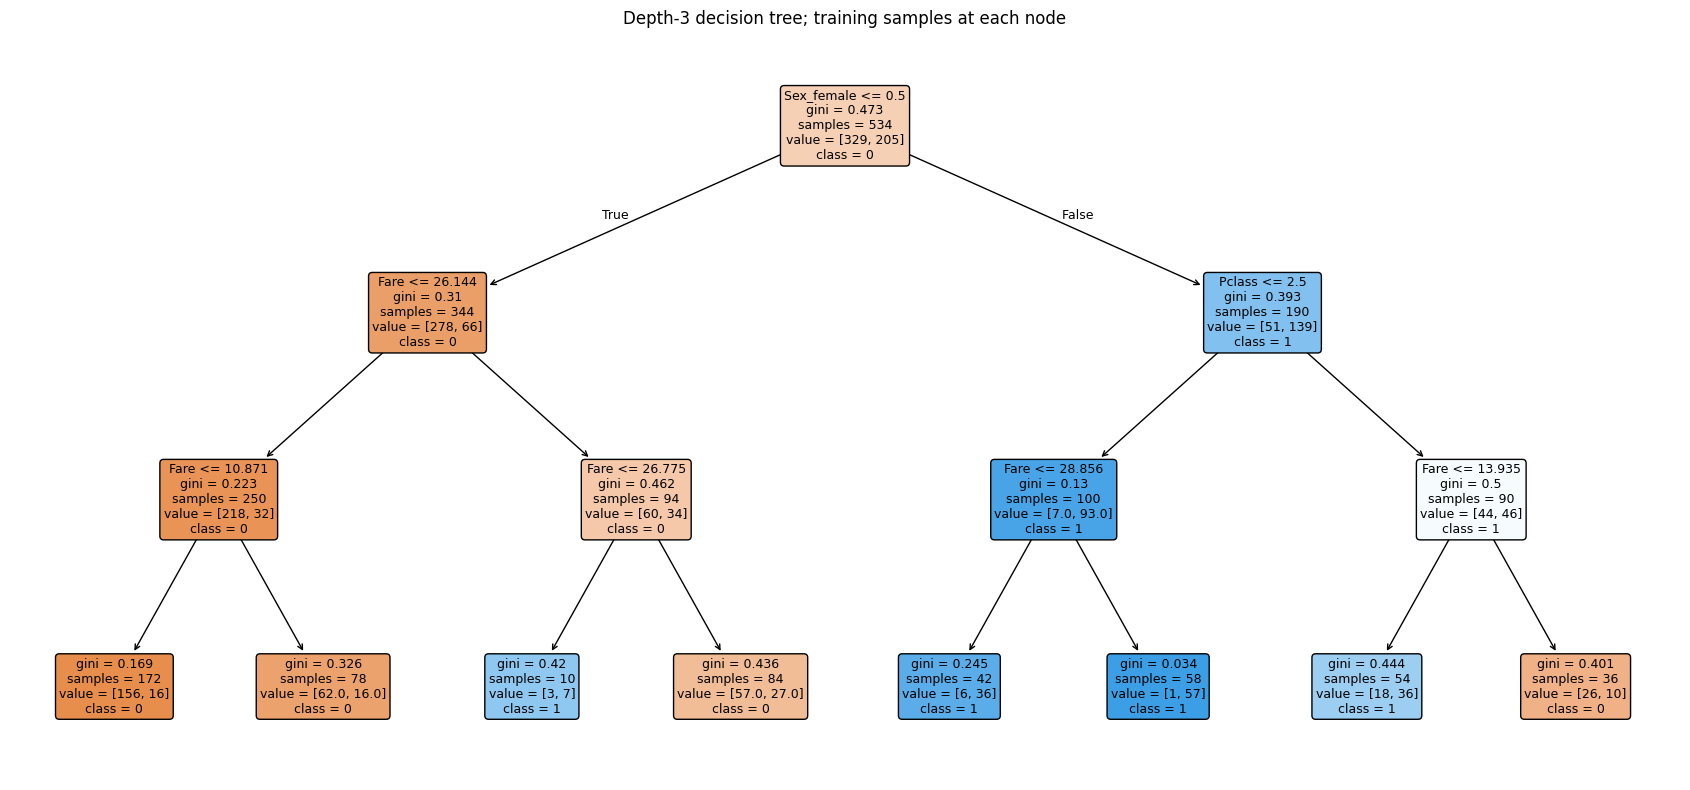

In [13]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# TODO: Create a depth-3 decision tree with random_state=42.
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
tree_valid_pred = tree.predict(X_valid)

print("Tree validation accuracy:", round(accuracy_score(y_valid, tree_valid_pred), 3))

plt.figure(figsize=(17, 8))
plot_tree(tree, feature_names=list(X.columns), class_names=["0", "1"],
          filled=True, rounded=True, fontsize=9)
plt.title("Depth-3 decision tree; training samples at each node")
plt.tight_layout()
# TODO: Fit only X_train/y_train and predict X_valid.
# TODO: Print validation accuracy.
# Optional: Plot the fitted tree with plot_tree.


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مدل دوم: رگرسیون لجستیک، با وجود نامش طبقه‌بند</strong><div>این مدل از ویژگی‌ها یک امتیاز خطی می‌سازد و آن را با تابع سیگموید به عددی بین صفر و یک تبدیل می‌کند. در طبقه‌بندی دودویی، خروجی <code>predict_proba</code> می‌تواند احتمال برآوردیِ برچسب ۱ را نشان دهد؛ <code>predict</code> با یک آستانهٔ تصمیم، برچسب ۰ یا ۱ می‌دهد. این عدد، قطعیت دربارهٔ سرنوشت یک فرد نیست. پیش از آموزش، ویژگی‌ها را با <code>StandardScaler</code> در یک <code>Pipeline</code> مقیاس می‌کنیم.</div></div>

### امتیاز خطی لجستیک

$$
z=w_0+\sum_{j=1}^{p}w_jx_j
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>عددهای <code>w</code> در زمان <code>fit</code> از دادهٔ آموزش یاد گرفته می‌شوند؛ هر <code>xⱼ</code> یک ستونِ عددیِ یک مسافر است.</div></div>

### تابع سیگموید

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>برای امتیاز بزرگِ مثبت، خروجی به ۱ نزدیک می‌شود؛ برای امتیاز بزرگِ منفی، به ۰ نزدیک می‌شود.</div></div>

### استانداردسازی فقط از آموزش

$$
x_{\mathrm{scaled}}=\frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>میانگین و انحراف معیار باید در <code>fit</code> از آموزش یاد گرفته شوند؛ همان تبدیل روی اعتبارسنجی اعمال می‌شود.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">رگرسیون لجستیک را در Pipeline اجرا کن</strong><div>دقت اعتبارسنجی و پنج احتمال برآوردیِ اول را ببین. <code>StandardScaler</code> در زمان <code>fit</code> فقط روی X_train تنظیم می‌شود.</div></div>

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# TODO: Build a StandardScaler + LogisticRegression(max_iter=1000) pipeline.
logistic = make_pipeline(StandardScaler() , LogisticRegression(max_iter=1000 , random_state=42) )
# TODO: Fit the pipeline on training data and predict validation data.
logistic.fit(X_train , y_train)
# TODO: Print accuracy and five P(y=1) estimates from predict_proba.
logistic_valid_pred = logistic.predict(X_valid)
print(logistic_valid_pred)
logistic_valid_prob = logistic.predict_proba(X_valid)[:, 1]
print(logistic_valid_prob)
accuracy_score(y_valid, logistic_valid_pred)

[0 0 0 0 1 0 0 0 1 0 1 1 0 1 1 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0
 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 1 0 0 1 0 1 1 1 0 1 0 0 0 0
 0 1 0 1 0 0 1 0 0 1 0 1 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 1 0 0 0 1 1 1 1 0 0 0 1 1 1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0 0 1 0 0 1 1
 0 1 1 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]
[0.1962168  0.374436   0.19310768 0.13154887 0.5473705  0.09175085
 0.16176908 0.09204175 0.54725882 0.09175085 0.94891012 0.55869018
 0.09169578 0.55646633 0.74089556 0.54665568 0.87499039 0.39462999
 0.09172581 0.09828865 0.09175085 0.89756662 0.09159071 0.09172581
 0.10483721 0.42309131 0.69750543 0.09187363 0.16179489 0.16176908
 0.374436   0.20313125 0.7511431  0.09171997 0.69750543 0.74089556
 0.1317653  0.1317653  0.92350094 0.19404586 0.09187363 0.88514713
 0.09175085 0.10192842 0.16885855 0.65114111 0.09171997 0.09204175
 0.19310768 0.09828865 0.16176637 0.88789396 0.1319499  0.74204762
 0.55153629 0.09439372 0.54677733 0

0.8033707865168539

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مدل سوم: نزدیک‌ترین همسایه‌ها</strong><div><code>KNeighborsClassifier(n_neighbors=7)</code> برای یک مسافر اعتبارسنجی، چند سطر آموزشیِ نزدیک را در فضای ویژگی‌ها می‌یابد و رأی آن‌ها را می‌گیرد. در این روش، <code>fit</code> عمدتاً نمونه‌های آموزش را نگه می‌دارد؛ هزینهٔ یافتن همسایه هنگام <code>predict</code> ظاهر می‌شود. چون فاصله به مقیاس حساس است، از همان ایدهٔ Pipeline برای استانداردسازی استفاده می‌کنیم.</div></div>

### فاصلهٔ اقلیدسی

$$
d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>پس از مقیاس‌کردن، این فرمول برای دو سطر عددی مقدار نزدیکی می‌سازد؛ فاصلهٔ کمتر یعنی نزدیک‌تر در همین نمایش انتخابی.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">هفت همسایه را امتحان کن</strong><div>مدل KNN را در Pipeline آموزش بده و دقت اعتبارسنجی را حساب کن. یک جمله بنویس: چرا <code>StandardScaler</code> اینجا اهمیت دارد؟</div></div>

In [30]:
from sklearn.neighbors import KNeighborsClassifier

# TODO: Make a StandardScaler + KNeighborsClassifier(n_neighbors=7) pipeline.
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))
knn.fit(X_train, y_train)

# TODO: Fit on training data and calculate validation accuracy.
knn_valid_pred = knn.predict(X_valid)
accuracy_score(y_valid, knn_valid_pred)


0.8146067415730337

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مدل چهارم: بیز سادهٔ گاوسی</strong><div><code>GaussianNB</code> از فراوانی کلاس‌ها و الگوی هر ویژگی در هر کلاس برای برآورد برچسب استفاده می‌کند. فرض «ساده» آن این است که ویژگی‌ها با دانستن کلاس مستقل شرطی‌اند. نسخهٔ گاوسی برای هر ویژگیِ عددی در هر کلاس شکل توزیع نرمال را فرض می‌کند. در این داده ستون‌های صفر/یک واقعاً نرمال نیستند و بعضی ستون‌های مجازی به هم وابسته‌اند؛ پس این مدل یک مقایسهٔ آموزشی با فرض‌های ناقص است، نه توصیف دقیق سازوکار مسافران.</div></div>

### قاعدهٔ تصمیم شهودی بیز ساده

$$
P(y=k\mid x)\propto P(y=k)\prod_{j=1}^{p}f_{j,k}(x_j)
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>برای هر برچسب، سهم پایهٔ آن برچسب و چگالیِ فرض‌شده برای ویژگی‌ها ترکیب می‌شوند. <code>f</code> در GaussianNB چگالی گاوسی است؛ علامت تناسب یعنی مخرج مشترک مقایسه حذف شده است.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بیز ساده را با همان تقسیم اجرا کن</strong><div>مدل را فقط روی آموزش <code>fit</code> کن و دقت اعتبارسنجی را ببین. یک فرض ساده‌ساز آن را از متن بالا نام ببر.</div></div>

In [25]:
from sklearn.naive_bayes import GaussianNB

naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)
nb_valid_pred = naive_bayes.predict(X_valid)
print("Naive Bayes validation accuracy:", round(accuracy_score(y_valid, nb_valid_pred), 3))


Naive Bayes validation accuracy: 0.742


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خودسنجی</strong><div>1) نام چهار مدلی را که اجرا کردیم بنویس و برای یکی شهودِ کارش را بگو.<br>2) در Pipeline، میانگین و انحراف معیار از کدام بخش داده یاد گرفته می‌شود؟<br>3) چرا نتیجهٔ GaussianNB برای ستون‌های صفر/یک باید با احتیاط تفسیر شود؟</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چهار مدل، یک اعتبارسنجی</strong><div>همهٔ مدل‌های بخش قبل با <code>X_train,y_train</code> آموزش دیده‌اند. حالا دقت آموزش و اعتبارسنجی را در یک جدول می‌گذاریم و با خط مبنا می‌سنجیم. مدل با بیشترین دقت اعتبارسنجی را برای گزارش نهایی انتخاب می‌کنیم؛ اگر چند مدل مساوی شدند، ترتیب ثابت جدول فقط یک قانون سادهٔ شکستن تساوی است. این مقایسه مربوط به یک تقسیم مشخص است و اختلاف کوچک را حقیقت همیشگی نمی‌نامیم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جدول مقایسه را بساز</strong><div>برای هر مدل دقت آموزش و اعتبارسنجی را حساب کن؛ کنار همه، دقت ثابت خط مبنا را نشان بده. مدل منتخب را فقط با دقت اعتبارسنجی مشخص کن.</div></div>

In [31]:
models = {
    "Decision tree": tree,
    "Logistic regression": logistic,
    "KNN": knn,
    "Gaussian naive Bayes": naive_bayes,
}
comparison_rows = []
for name , estimator in models.items():
    train_pred = estimator.predict(X_train)
    valid_pred = estimator.predict(X_valid) 
    comparison_rows.append({
        "model": name,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "validation_accuracy": accuracy_score(y_valid, valid_pred),
    })   

model_report = pd.DataFrame(comparison_rows).set_index("model")
model_report
# TODO: For each model calculate train and validation accuracy.
# TODO: Add the same majority baseline validation accuracy to the table.
# TODO: Select the model with the greatest validation accuracy.


,train_accuracy,validation_accuracy
model,,
Decision tree,0.818352,0.803371
Logistic regression,0.771536,0.803371
KNN,0.831461,0.814607
Gaussian naive Bayes,0.730337,0.741573


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">دقت چه خطاهایی را پنهان می‌کند؟</strong><div>ماتریس خطا یک جدول ۲×۲ است: ردیف‌ها برچسب واقعی و ستون‌ها حدس مدل. برای کلاس ۱ که در این فایل «زنده‌مانده» است، چهار حالت <code>TP</code>، <code>FP</code>، <code>FN</code> و <code>TN</code> را می‌خوانیم. دقت شمار درست‌های هر دو کلاس را با هم جمع می‌کند؛ بازخوانی و دقتِ مثبت‌ها پرسش‌های دقیق‌تری دربارهٔ کلاس ۱ می‌پرسند.</div></div>

### دقت از چهار خانه

$$
\operatorname{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>دو خانهٔ قطر اصلی پیش‌بینی درست‌اند؛ جمع چهار خانه باید برابر تعداد سطرهای اعتبارسنجی باشد.</div></div>

### بازخوانی کلاس ۱

$$
\operatorname{Recall}_{1}=\frac{TP}{TP+FN}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>از بین واقعاً برچسب‌یک‌ها، چه نسبتی را مدل یک گفته است؟</div></div>

### دقتِ پیش‌بینی‌های ۱

$$
\operatorname{Precision}_{1}=\frac{TP}{TP+FP}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">این فرمول چه می‌گوید؟</strong><div>از بین سطرهایی که مدل برچسب ۱ داده، چه نسبتی واقعاً ۱ بوده‌اند؟</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ماتریس خطا را از اعتبارسنجی بخوان</strong><div>برای مدل منتخب جدول را بساز؛ از خود چهار خانه precision و recall کلاس ۱ را حساب کن و با تابع کتابخانه تطبیق بده. نوع خطای <code>Actual 1 / Predicted 0</code> را بگو.</div></div>

In [39]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# TODO: Predict X_valid using the selected model.
selected_valid_pred = models["KNN"].predict(X_valid)
cm = confusion_matrix(y_valid, selected_valid_pred, labels=[0, 1])
cm
cm_table = pd.DataFrame(cm, index=["Actual 0", "Actual 1"],
                        columns=["Predicted 0", "Predicted 1"])
display(cm_table)
cm.ravel()
manual_recall = cm.ravel()[3] /(cm.ravel()[3] + cm.ravel()[2])
manual_precision =  cm.ravel()[3] /(cm.ravel()[3] + cm.ravel()[1])
precision_score_ = precision_score(y_valid, selected_valid_pred)
recall_score_ = recall_score(y_valid, selected_valid_pred)
# TODO: Build a confusion matrix with actual labels as rows and predictions as columns.
# TODO: Calculate TP, FP, FN, TN and class-1 precision/recall manually.
# TODO: Check the four cells sum to len(X_valid).
print(manual_recall , manual_precision,  recall_score_ , precision_score_)

,Predicted 0,Predicted 1
Actual 0,99,11
Actual 1,22,46


0.6764705882352942 0.8070175438596491 0.6764705882352942 0.8070175438596491


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بیش‌برازش را از دو ستون دقت ببین</strong><div>سه عمق <code>1</code>، <code>3</code> و بدون محدودیت را از پیش برای یک نمایش آموزشی تعیین می‌کنیم. هر مدل تازه فقط روی آموزش fit می‌شود. اگر دقت آموزش بالا برود اما اعتبارسنجی همان قدر بهتر نشود یا افت کند، ممکن است درخت جزئیاتِ خاص آموزش را بیشتر یاد گرفته باشد. این آزمایش روی <code>X_valid</code> است؛ هرگز برای انتخاب عمق سراغ آزمون نهایی نمی‌رویم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">سه عمقِ از پیش تعیین‌شده را مقایسه کن</strong><div>جدول دقت آموزش و اعتبارسنجی را بساز. زیر نمودار یک جمله دربارهٔ فاصلهٔ دو دقت بنویس؛ عددهای واقعی همین اجرا را توصیف کن.</div></div>

,train_accuracy,validation_accuracy
depth,,
1,0.781,0.803
3,0.818,0.803
unrestricted,0.919,0.848


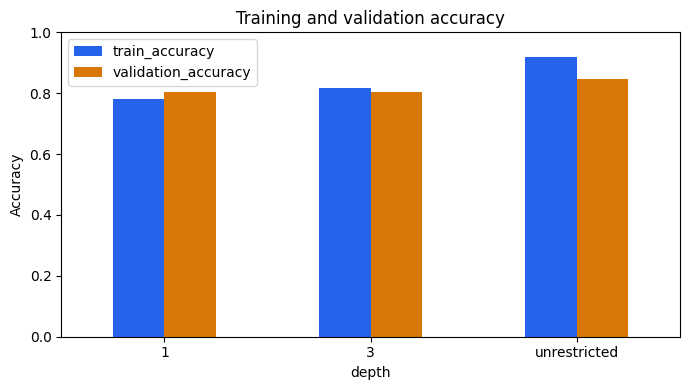

In [40]:
depth_rows = []
for label, depth in [("1", 1), ("3", 3), ("unrestricted", None)]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    candidate.fit(X_train, y_train)
    depth_rows.append({
        "depth": label,
        "train_accuracy": accuracy_score(y_train, candidate.predict(X_train)),
        "validation_accuracy": accuracy_score(y_valid, candidate.predict(X_valid)),
    })
depth_report = pd.DataFrame(depth_rows).set_index("depth")
display(depth_report.round(3))
ax = depth_report.plot(kind="bar", figsize=(7, 4), ylim=(0, 1), rot=0,
                       color=["#2563eb", "#d97706"])
ax.set_ylabel("Accuracy")
ax.set_title("Training and validation accuracy")
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین مستقل: آیا بندر چیزی به مدل اضافه می‌کند؟</strong><div>با همان سطرهای آموزش و اعتبارسنجی، دو درختِ عمق ۳ بساز: الف) همهٔ ستون‌های X؛ ب) همهٔ ستون‌ها به‌جز چهار ستون <code>Embarked_...</code>. برای هر دو دقت آموزش و اعتبارسنجی را گزارش کن. مقایسه فقط دربارهٔ این داده، این تقسیم و این مدل است؛ به‌تنهایی ثابت نمی‌کند بندر سوارشدن علتِ بقاست. با دیدن این مقایسه، مدل منتخبِ جدول چهارمدلی را عوض نکن؛ این بخش یک آزمایش اکتشافی در اعتبارسنجی است.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">آزمایش حذفِ ستون‌های بندر</strong><div>ستون‌های بندر را از <code>X_train</code> و <code>X_valid</code> کنار بگذار؛ هر دو درخت عمق ۳ باشند. جدول دقت و یک جملهٔ محتاطانه دربارهٔ نتیجه بنویس.</div></div>

In [46]:
# TODO: Make a feature list without any Embarked_ column.
# TODO: Fit two new depth-3 trees on the same training rows.
# TODO: Compare training and validation accuracy on the same rows.
# TODO: Explain why a score difference does not prove causation.
all_columns = list(X_train.columns)
feature_rows = []
without_port = [column for column in all_columns if column not in port_columns]
for name, columns in [("all", all_columns), ("without Embarked", without_port)]:
    candidate = DecisionTreeClassifier(max_depth=None, random_state=42)
    candidate.fit(X_train[columns], y_train)
    feature_rows.append({
        "features": name,
        "train_accuracy": accuracy_score(y_train, candidate.predict(X_train[columns])),
        "validation_accuracy": accuracy_score(y_valid, candidate.predict(X_valid[columns])),
    })
feature_report = pd.DataFrame(feature_rows).set_index("features")
feature_report

,train_accuracy,validation_accuracy
features,,
all,0.919476,0.848315
without Embarked,0.917603,0.837079


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #be185d;border-radius:8px;background:rgba(236,72,153,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">فقط اکنون: یک گزارش نهایی روی آزمون</strong><div>نام مدلِ انتخاب‌شده در جدول اعتبارسنجی از قبل مشخص شده است. اکنون مدل تازه‌ای از همان نوع می‌سازیم، آن را روی آموزش و اعتبارسنجی با هم fit می‌کنیم و <b>یک‌بار</b> روی X_test پیش‌بینی می‌کنیم. عدد آزمون برای بازگشت و انتخاب دوبارهٔ مدل، ویژگی یا عمق استفاده نمی‌شود. برای مقایسه، خط مبنای اکثریت را هم از پاسخ‌های آموزش+اعتبارسنجی می‌سازیم و روی همان آزمون می‌سنجیم.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مدلِ از پیش انتخاب‌شده را یک‌بار روی آزمون بسنج</strong><div>انتخاب مدل را تغییر نده. پس از fit روی آموزش+اعتبارسنجی، دقت نهایی و خط مبنا را روی سطرهای آزمون چاپ کن. در گزارش بنویس این نتیجه مربوط به همین داده و همین تقسیم است.</div></div>

In [48]:
from sklearn.base import clone

X_dev = pd.concat([X_train, X_valid])
y_dev = pd.concat([y_train, y_valid])
final_model = clone(models["Decision tree"])
final_model.fit(X_dev, y_dev)
final_test_pred = final_model.predict(X_test)
final_test_accuracy = accuracy_score(y_test, final_test_pred)
final_majority = int(y_dev.value_counts().idxmax())
final_baseline_pred = np.full(len(y_test), final_majority, dtype=int)
final_baseline_accuracy = accuracy_score(y_test, final_baseline_pred)
print("Chosen on validation:", "Decision tree")
print("Final test accuracy:", round(final_test_accuracy, 3))
print("Final majority baseline on same test rows:", round(final_baseline_accuracy, 3))
print("Final test rows:", len(y_test))


Chosen on validation: Decision tree
Final test accuracy: 0.816
Final majority baseline on same test rows: 0.615
Final test rows: 179


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خودسنجی</strong><div>1) از کدام بخش داده مدل برنده را انتخاب کردیم و آزمون را چند بار سنجیدیم؟<br>2) اگر TP=8، FN=2 و FP=4 باشد، recall و precision کلاس ۱ چقدر است؟<br>3) چرا بهتر شدن دقت با اضافه شدن Embarked اثباتِ علّی نیست؟</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین خانه؛ انتقال روش به یک دادهٔ تازه</strong><div>روی دادهٔ پنگوئن‌های تمرین قبلی، با <code>body_mass_g</code> و <code>flipper_length_mm</code> گونه را پیش‌بینی کن. فقط سطرهای دارای این دو اندازه و گونه را نگه دار. داده را با حفظ تقریبی نسبت کلاس‌ها به آموزش/اعتبارسنجی/آزمون تقسیم کن؛ خط مبنا، درخت و KNN مقیاس‌شده را روی اعتبارسنجی مقایسه کن؛ مدل منتخب را یک‌بار روی آزمون بسنج. یک پاراگراف محدودیت تحلیل بنویس.</div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">منابع و روش اجرا</strong><div><a href="https://github.com/datasciencedojo/datasets/blob/master/titanic.csv">فایل Titanic</a>؛ <a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html">OneHotEncoder</a>؛ <a href="https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html">پیش‌پردازش و Pipeline</a>؛ <a href="https://scikit-learn.org/stable/modules/cross_validation.html">ارزیابی و اعتبارسنجی</a>؛ <a href="https://scikit-learn.org/stable/common_pitfalls.html">دام‌های رایج و نشت اطلاعات</a>.<br>پس از تکمیل TODOها، نوت‌بوک را از ابتدا اجرا کن و فایل اجراشده را ذخیره کن. پوشهٔ <code>data</code> را برای کار آفلاین کنار فایل نگه دار.</div></div>